# Hälsostudie

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats
np.random.seed(45)      # Använder slump med repeterbar seed.


df = pd.read_csv("health_study_dataset.csv")        # Läser in csv-fil.

df.info()


<class 'pandas.DataFrame'>
RangeIndex: 800 entries, 0 to 799
Data columns (total 9 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   id           800 non-null    int64  
 1   age          800 non-null    int64  
 2   sex          800 non-null    str    
 3   height       800 non-null    float64
 4   weight       800 non-null    float64
 5   systolic_bp  800 non-null    float64
 6   cholesterol  800 non-null    float64
 7   smoker       800 non-null    str    
 8   disease      800 non-null    int64  
dtypes: float64(4), int64(3), str(2)
memory usage: 56.4 KB


> **Kommentar:** Datasetet består av 800 rader och 9 kolumner. Samtliga kolumner har 800 non-null-värden, vilket visar att datasetet inte innehåller några saknade värden (NaN) och att datatyperna är korrekta inför analysen.

## Beskrivande analys

In [2]:
# Räknar ut medel, median, min och max för kolumnerna ålder, vikt, längd, blodtryck och kolesterol
statistics = df[["age", "weight", "height", "systolic_bp", "cholesterol"]].agg(
    ["mean", "median", "min", "max"]
).round(1)

statistics



,age,weight,height,systolic_bp,cholesterol
mean,49.4,73.4,171.8,149.2,4.9
median,50.0,73.2,171.4,149.4,5.0
min,18.0,33.7,144.4,106.8,2.5
max,90.0,114.4,200.4,185.9,7.9


> **Kommentar:** Sammanställningen visar att medelvärde och median ligger mycket nära varandra för samtliga variabler, vilket tyder på symmetriska fördelningar. Deltagarna är mellan 18 och 90 år med en medelålder på cirka 49,4 år. Värt att notera är att det systoliska blodtrycket varierar stort i gruppen, från 106,8 till 185,9 mmHg. Dessutom sticker det låga minimivärdet för vikt (33,7 kg) ut. Vid en närmare kontroll av datan visade det sig tillhöra en 75-årig kvinna. Det går inte att avgöra utifrån datan om det rör sig om ett verkligt extremvärde eller ett inmatningsfel, men värdet behålls i analysen.

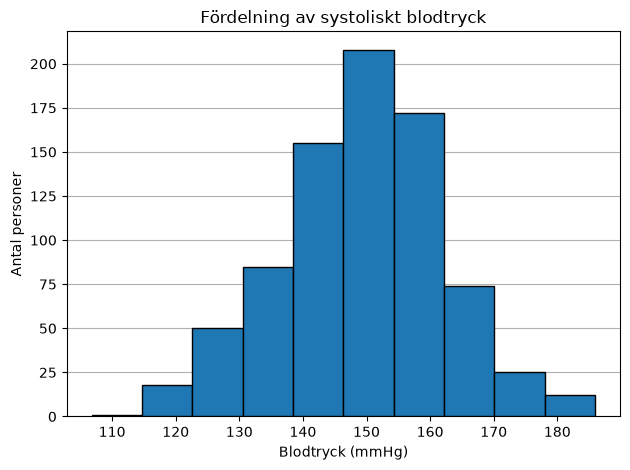

In [3]:
fig, ax = plt.subplots()
ax.hist(df["systolic_bp"], bins=10, edgecolor="black", zorder=3)        # 10 staplar med svart kant. Sätter staplarna framför grid med zorder.
ax.set_title("Fördelning av systoliskt blodtryck")
ax.set_xlabel("Blodtryck (mmHg)")
ax.set_ylabel("Antal personer")
ax.grid(True, axis="y")
plt.tight_layout()
plt.show()

>**Figur 1.** Fördelningen av systoliskt blodtryck i datasetet. Diagrammet visar att värdena är relativt normalfördelade (klockformade) och att majoriteten av personerna har ett systoliskt blodtryck mellan 140 och 160 mmHg. Den största enskilda gruppen ligger runt 150 mmHg, medan det finns få extremvärden under 120 och över 170 mmHg.


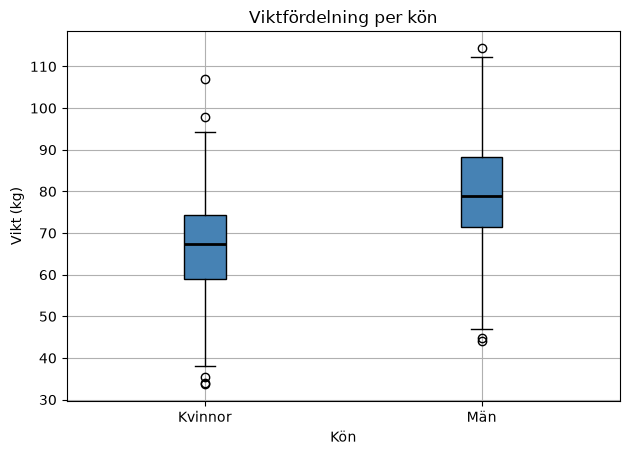

In [4]:
fig, ax =plt.subplots()
df.boxplot(column="weight", by="sex", ax=ax, patch_artist=True,         # Gör så att man kan färglägga (patch_artist).
    boxprops=dict(facecolor="steelblue", color="black"),                # Färglägger boxarna blåa med svart kant.
    medianprops=dict(color="black", linewidth=2),                       # Gör medianlinjen svart och grövre.
    whiskerprops=dict(color="black"),
    capprops=dict(color="black"))
ax.set_title("Viktfördelning per kön")
ax.set_xlabel("Kön")
ax.set_xticklabels(["Kvinnor", "Män"])
ax.set_ylabel("Vikt (kg)")
plt.suptitle("")
plt.tight_layout()
plt.show()

>**Figur 2.** Diagrammet visar viktfördelningen uppdelat per kön. Generellt väger männen mer än kvinnorna, med en median på cirka 79 kg jämfört med cirka 67 kg för kvinnor (markerat med det svarta strecket inuti respektive låda). De mittersta 50 % av kvinnorna väger mellan cirka 59 och 74 kg, medan motsvarande grupp för männen ligger mellan cirka 72 och 88 kg. Båda grupperna har enstaka extremvärden (outliers), vilka visas som cirklar ovanför och nedanför linjerna.

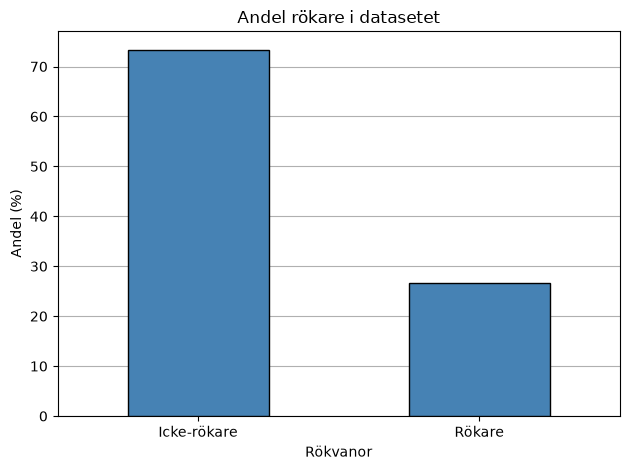

In [5]:
fig, ax = plt.subplots()
proportion_of_smokers = df["smoker"].value_counts(normalize=True) * 100                 # Räknar antal olika påstående (yes/no) i kolumnen och räknar ut fördelningen i procent.
proportion_of_smokers.plot(kind="bar", ax=ax, color="steelblue", edgecolor="black", zorder=3)

ax.set_title("Andel rökare i datasetet")
ax.set_xlabel("Rökvanor")
ax.set_ylabel("Andel (%)")
ax.set_xticklabels(["Icke-rökare", "Rökare"], rotation=0)
ax.grid(True, axis="y")
plt.tight_layout()
plt.show()



>**Figur 3.** Av 800 personer är ca 27 % rökare och 73 % icke-rökare.

## Simulering kopplad till caset

In [6]:
# Verklig andel i datasetet.
n_disease = df["disease"].sum()         # Räknar ut antalet som har sjukdomen
proportion_of_disease = (n_disease / len(df["disease"])) * 100              # Andel personer som har sjukdomen i procent.
print(f"Det är {n_disease} personer i datasetet som har sjukdomen, vilket är ca {proportion_of_disease:.1f} % av personerna.")

# Simulering av 1000 personer.
sim_disease_1000 = np.random.binomial(n=1, p=proportion_of_disease/100, size=1000)      # Simulerar sjukdom på 1000 personer med en slump på ca 5,9%. Gör om från procent till decimaltal.
n_sim_disease = sim_disease_1000.sum()
sim_porportion = (n_sim_disease / len(sim_disease_1000)) * 100          # Andel simulerade personer som har sjukdomen, i procent.
print()
print(f"Antalet simulerade sjukdomsfall på 1000 personer med samma sannolikhet som datasetet är {n_sim_disease} personer.\nVilket ger en andel på {sim_porportion} % för simuleringen.")

# Jämförelse av andelar
diff = sim_porportion - proportion_of_disease
print()
print(f"Skillnad mellan simulerad och verklig andel: {diff:.1f} procentenheter.")

Det är 47 personer i datasetet som har sjukdomen, vilket är ca 5.9 % av personerna.

Antalet simulerade sjukdomsfall på 1000 personer med samma sannolikhet som datasetet är 57 personer.
Vilket ger en andel på 5.7 % för simuleringen.

Skillnad mellan simulerad och verklig andel: -0.2 procentenheter.


>**Kommentar:** Den simulerade andelen ligger nära den verkliga. Skillnaden beror på slumpmässig variation.

## Konfidensintervall

### Normalapproximation

In [7]:
bp = df["systolic_bp"]
n_bp = len(bp)
mean_bp = bp.mean()
std = bp.std(ddof=1)  # Stickprovsstandardavvikelse
z = 1.96                # z-värdet, används för att räkna ut felmarginalen

se = std / np.sqrt(n_bp)    # Standardfel
margin_of_error = z * se    # Felmarginal

ci_low = mean_bp - margin_of_error      # Konfidensintervallets lägsta punkt.
ci_high = mean_bp + margin_of_error     # Konfidensintervallets högsta punkt.

print(f"Medelvärdet för systoliskt blodtryck är {mean_bp:.1f} mmHg för personerna i denna hälsostudie.")
print(f"Det 95-procentiga konfidensintervallet är mellan {ci_low:.1f} och {ci_high:.1f} med normalapproximation.")


Medelvärdet för systoliskt blodtryck är 149.2 mmHg för personerna i denna hälsostudie.
Det 95-procentiga konfidensintervallet är mellan 148.3 och 150.1 med normalapproximation.


>**Kommentar:** Uträkningen med normalapproximationen ger med 95 % säkerhet att det sanna medelvärdet för hela populationen ligger någonstans i mellan 148,3 och 150,1 mmHg.

### Bootstrap

In [8]:
bp_boot = df["systolic_bp"].values
n_bp_boot = len(bp_boot)            # Har samma storlek som originaldatan.
n_bootstrap = 10000                 # 10000 rundor

boot_means = []                     # Skapar en ny array för att lagra medelvärdena från bootstrap-stickproven.
for _ in range(n_bootstrap):
    sample = np.random.choice(bp_boot, size=n_bp_boot, replace=True)        # Väljer slumpmässigt ut värden från kolumnen med blodtryck med återläggning.
    boot_means.append(sample.mean())               # Sparar medelvärdet i listan.             


boot_low = np.percentile(boot_means, 2.5)
boot_high = np.percentile(boot_means, 97.5)
boot_mean = np.mean(boot_means)

print(f"Bootstrap-medelvärdet blir {boot_mean:.1f} mmHg.")
print(f"Det 95-procentiga konfidensintervallet enligt Bootstrap-metoden ligger mellan {boot_low:.1f} och {boot_high:.1f} mmHg")


Bootstrap-medelvärdet blir 149.2 mmHg.
Det 95-procentiga konfidensintervallet enligt Bootstrap-metoden ligger mellan 148.3 och 150.1 mmHg


> **Kommentar:** Bootstrap-beräkningen ger ett medelvärde på 149,2 mmHg och ett 95-procentiskt konfidensintervall mellan 148,3 och 150,1 mmHg. Resultatet är identiskt med normalapproximationen, vilket beror på att urvalet är stort (800 observationer) och att datan är symmetriskt fördelad.


## Hypotesprövning

* Nollhypotes: Det finns ingen skillnad i medel-blodtryck mellan rökare och icke-rökare.

* Alternativhypotes: Rökare har högre medel-blodtryck än icke-rökare.

* Signifikansnivå: 0,05 (5 %). Om p-värdet blir mindre än 0,05 förkastas nollhypotesen.

In [9]:
bp_smoker = df[df["smoker"] == "Yes"]["systolic_bp"]
bp_non_smoker = df[df["smoker"] == "No"]["systolic_bp"]

t_stat_w, p_value_w = stats.ttest_ind(bp_smoker, bp_non_smoker, equal_var=False, alternative="greater")        # Gör ett ensidigt (större än) Welch t-test.

print(f"Medelblodtryck rökare: {bp_smoker.mean():.1f} mmHg")
print(f"Medelblodtryck icke-rökare: {bp_non_smoker.mean():.1f} mmHg")
print(f"t-värde: {t_stat_w:.2f}, p-värde: {p_value_w:.3f}")


Medelblodtryck rökare: 149.5 mmHg
Medelblodtryck icke-rökare: 149.1 mmHg
t-värde: 0.45, p-värde: 0.326


>**Kommentar:** Medelblodtrycket för rökare är 149,5 mmHg och för icke-rökare är det 149,1 mmHg. Det är en väldigt liten skillnad. Jämför man p-värdet (0,326) mot signifikansnivån (0,05), så ser man att p-värdet är större och därför kan vi inte förkasta nollhypotesen, vilken säger att det inte finns någon skillnad i blodtryck mellan rökare och icke-rökare i denna hälsostudie. Resultatet visar att den skillnad vi ser kan bero på slumpen.

## Simulering med power för att se hur säkert hypotestestet är.

In [10]:
n_smoker = len(bp_smoker)                   # Antal rökare.
n_non_smoker = len(bp_non_smoker)           # Antal icke-rökare.
mean_non_smoker = bp_non_smoker.mean()      # Medelblodtryck för icke-rökare. Används som utgångspunkt (baslinje).
std_dev_bp = df["systolic_bp"].std(ddof=1)  # Standardavvikelsen (spridningen) för blodtrycket.

real_diff = 3.0                             # Antar en verklig skillnad på 3 mmHg mellan rökare och icke-rökare, för att testa hur bra testet är på att upptäcka den.
n_of_simulation = 10000                     # Antal simuleringar.
n_of_significant_tests = 0                  # Antalet tester som är statistiskt signifikanta. Börjar på 0.


for _ in range(n_of_simulation):            # En loop som kör simuleringen 10000 gånger.
    sim_non_smoker = np.random.normal(loc=mean_non_smoker, scale=std_dev_bp, size=n_non_smoker)             # Simulerar blodtryck för icke-rökare, utifrån deras medelvärde,normalfördelning, spridning och antal i studien.
    sim_smoker = np.random.normal(loc=mean_non_smoker + real_diff, scale=std_dev_bp, size=n_smoker)         # Simulerar blodtryck för rökare med ett medelvärde som är 3 mmHg högre, men med samma spridning och antal som i studien.
    
    _, p_val = stats.ttest_ind(sim_smoker, sim_non_smoker, equal_var=False, alternative="greater")          # Räknar ut p-värdet med Welch's t-test under antagandet att rökare har högre blodtryck.
    
    if p_val < 0.05:                        # Om p-värdet är mindre än signifikansnivån (0,05) räknas antalet signifikanta test upp med 1.
        n_of_significant_tests += 1

power = n_of_significant_tests / n_of_simulation
print(f"Simulerad power för en skillnad på {real_diff} mmHg är {power * 100:.1f} %.")

Simulerad power för en skillnad på 3.0 mmHg är 90.2 %.


>**Kommentar:** Power räknar ut chansen att hitta en skillnad mellan två grupper. Här gör vi en simulering på 10 000 tester med 800 personer i varje test, där det antas att rökare i medel har 3 mmHg högre blodtryck. Resultatet 90,2 % betyder att om rökare i genomsnitt har 3 mmHg högre blodtryck än icke-rökare, så hade denna skillnad upptäckts med 90,2 % sannolikhet i en studie på 800 personer. Detta visar att urvalsstorleken var tillräcklig för denna hälsostudie, och att uteblivet signifikant resultat i studien sannolikt beror på att den faktiska skillnaden är mindre än 3 mmHg.

## Metodval och källor

* **Simulering av sjukdomsfrekvens:** För att simulera sjukdomsutfall på 1 000 slumpade personer användes `np.random.binomial`, eftersom variabeln `disease` är binär (sjuk/frisk) och har en given sannolikhet utifrån datasetet.
* **Konfidensintervall:** Både normalapproximation och bootstrap (10 000 omval med återläggning) användes för att beräkna ett 95 % konfidensintervall för systoliskt blodtryck. Normalapproximation valdes då stickprovet är stort och datan är normalfördelad, medan bootstrap användes som komplement för att bekräfta att intervallet är stabilt.
* **Hypotesprövning:** Welch’s t-test (`equal_var=False`) valdes för att jämföra medelblodtrycket mellan rökare och icke-rökare, eftersom gruppstorlekarna skiljer sig åt och lika varians inte kan antas. Testet kördes ensidigt (`alternative="greater"`) eftersom alternativhypotesen specifikt prövar om rökare har ett högre blodtryck.
* **Power-analys:** Styrkeberäkningen genomfördes som en simulering med `np.random.normal` (10 000 körningar), då histogrammet visade att blodtrycket i datasetet är ungefär normalfördelat. En skillnad på 3,0 mmHg (cirka 2 % av medelvärdet) valdes som en rimlig minsta effekt på gruppnivå.

### Källor
* NumPy Documentation – [numpy.random.binomial] (https://numpy.org/doc/2.5/reference/random/generated/numpy.random.binomial.html)
* NumPy Documentation – [numpy.random.choice] (https://numpy.org/doc/2.5/reference/random/generated/numpy.random.choice.html)
* NumPy Documentation – [numpy.random.normal] (https://numpy.org/doc/2.3/reference/random/generated/numpy.random.normal.html)
* SciPy Documentation – [scipy.stats.ttest_ind] (https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.ttest_ind.html)